In [87]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize 

In [ ]:

df = pd.read_csv('C:\\Users\\User\\OneDrive\\Desktop\\I am python\\15stocks_price.csv')
df.set_index('date_gsheets', inplace=True)
df.head()

,RELIANCE.NS,TCS.NS,INFY.NS,HDFCBANK.NS,ICICIBANK.NS,HINDUNILVR.NS,ITC.NS,BAJFINANCE.NS,KOTAKBANK.NS,LT.NS,BHARTIARTL.NS,SBIN.NS,SUNPHARMA.NS,MARUTI.NS,NTPC.NS
date_gsheets,,,,,,,,,,,,,,,
02/08/21 16:00,938.672424,2796.687500,1421.035156,665.656128,655.445618,2139.020996,163.225983,604.642822,331.062958,1533.898926,535.436951,397.823547,735.717285,6715.373047,97.092873
03/08/21 16:00,945.579346,2853.588135,1441.633545,671.294250,664.102783,2188.581055,165.273193,617.456360,335.148773,1553.287109,549.695679,408.434631,754.513611,6831.566406,97.010414
04/08/21 16:00,952.826111,2844.075684,1436.451294,685.612000,687.429138,2179.640869,164.249619,620.113647,347.933197,1542.690186,544.200684,417.993805,745.922302,6739.997070,97.175323
05/08/21 16:00,966.640137,2852.762695,1440.196655,694.759399,675.693848,2161.852295,169.485733,609.299194,352.267639,1546.681885,567.223022,404.181091,746.302002,6711.013672,96.062149
06/08/21 16:00,946.168213,2875.218506,1437.278809,698.409058,671.076599,2174.505859,168.698364,606.963623,353.351227,1530.477417,575.939331,398.509644,745.400330,6780.964844,97.010414


In [21]:
returns_df = df.pct_change().dropna()
returns_df.head()

,RELIANCE.NS,TCS.NS,INFY.NS,HDFCBANK.NS,ICICIBANK.NS,HINDUNILVR.NS,ITC.NS,BAJFINANCE.NS,KOTAKBANK.NS,LT.NS,BHARTIARTL.NS,SBIN.NS,SUNPHARMA.NS,MARUTI.NS,NTPC.NS
date_gsheets,,,,,,,,,,,,,,,
03/08/21 16:00,0.007358,0.020346,0.014495,0.008470,0.013208,0.023170,0.012542,0.021192,0.012342,0.012640,0.026630,0.026673,0.025548,0.017303,-0.000849
04/08/21 16:00,0.007664,-0.003334,-0.003595,0.021329,0.035125,-0.004085,-0.006193,0.004304,0.038146,-0.006822,-0.009996,0.023404,-0.011387,-0.013404,0.001700
05/08/21 16:00,0.014498,0.003054,0.002607,0.013342,-0.017071,-0.008161,0.031879,-0.017439,0.012458,0.002587,0.042305,-0.033045,0.000509,-0.004300,-0.011455
06/08/21 16:00,-0.021178,0.007872,-0.002026,0.005253,-0.006833,0.005853,-0.004646,-0.003833,0.003076,-0.010477,0.015367,-0.014032,-0.001208,0.010423,0.009871
09/08/21 16:00,-0.005696,0.003897,0.007938,0.007537,0.007454,0.005482,-0.002101,-0.005004,0.002082,-0.008011,-0.014229,-0.005165,0.004585,-0.002683,-0.008075


In [24]:
returns_df.mean()

RELIANCE.NS      0.000343
TCS.NS          -0.000021
INFY.NS         -0.000048
HDFCBANK.NS      0.000136
ICICIBANK.NS     0.000714
HINDUNILVR.NS    0.000018
ITC.NS           0.000435
BAJFINANCE.NS    0.000602
KOTAKBANK.NS     0.000292
LT.NS            0.000888
BHARTIARTL.NS    0.001064
SBIN.NS          0.000900
SUNPHARMA.NS     0.000868
MARUTI.NS        0.000665
NTPC.NS          0.001083
dtype: float64

In [ ]:
# 1. Define portfolio risk (Annualized Volatility) as the objective function
def getportreturn(weights):
    exp_ret_portfolio = np.dot(np.transpose(weights), returns_df.mean()) * 252

    return exp_ret_portfolio

In [30]:
num_stocks = len(returns_df.columns)
init_weights = [1/num_stocks] * num_stocks
getportreturn(init_weights)

np.float64(0.13336750687499802)

In [ ]:
# 2. Constraints: Weights must sum to 1, and reach a realistic target return (e.g., 20%)
target_return= 0.25

In [60]:
bounds = tuple([(0, 1) for _ in range(num_stocks)])
bounds

((0, 1),
 (0, 1),
 (0, 1),
 (0, 1),
 (0, 1),
 (0, 1),
 (0, 1),
 (0, 1),
 (0, 1),
 (0, 1),
 (0, 1),
 (0, 1),
 (0, 1),
 (0, 1),
 (0, 1))

In [ ]:
cons = (
    {'type': 'eq', 'fun': lambda x: np.sum(x) - 1},
    {'type': 'eq', 'fun': lambda x: x.dot(returns_df.mean()) * 252 - target_return}
)

In [84]:
# 3. Minimize RISK (volatility)
results = minimize(fun = getportreturn, x0 = init_weights, bounds = bounds, constraints = cons)

In [83]:
results

     message: Optimization terminated successfully
     success: True
      status: 0
         fun: 0.250000000363233
           x: [ 0.000e+00  2.776e-17 ...  0.000e+00  2.930e-01]
         nit: 2
         jac: [ 8.638e-02 -5.296e-03 ...  1.676e-01  2.729e-01]
        nfev: 32
        njev: 2
 multipliers: [ 9.944e-11  1.000e+00]

In [71]:
getportreturn(weights = results['x'])

np.float64(0.2728888597590319)

In [85]:
weights_df = pd.DataFrame({'Weight': results.x}, index=returns_df.columns)
weights_df['Weight (%)'] = (weights_df['Weight'] * 100).round(2)
print(weights_df)

                     Weight  Weight (%)
RELIANCE.NS    0.000000e+00        0.00
TCS.NS         2.775558e-17        0.00
INFY.NS        2.775558e-17        0.00
HDFCBANK.NS    6.938894e-17        0.00
ICICIBANK.NS   7.675356e-03        0.77
HINDUNILVR.NS  0.000000e+00        0.00
ITC.NS         0.000000e+00        0.00
BAJFINANCE.NS  0.000000e+00        0.00
KOTAKBANK.NS   0.000000e+00        0.00
LT.NS          1.427577e-01       14.28
BHARTIARTL.NS  2.784564e-01       27.85
SBIN.NS        1.515425e-01       15.15
SUNPHARMA.NS   1.265840e-01       12.66
MARUTI.NS      0.000000e+00        0.00
NTPC.NS        2.929841e-01       29.30


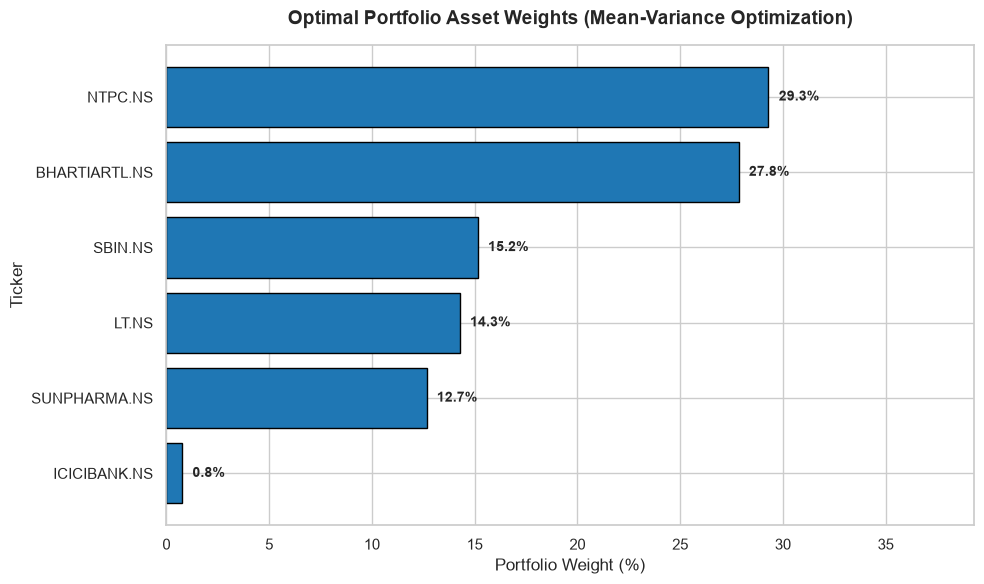

In [88]:
# 1. Format weights into a clean Pandas Series
tickers = returns_df.columns
weights_series = pd.Series(results['x'], index=tickers) * 100  # Convert to percentage

# Filter out negligible allocations (e.g., < 0.1%)
weights_series = weights_series[weights_series > 0.1].sort_values(ascending=True)

# 2. Plot horizontal bar chart
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

bars = plt.barh(weights_series.index, weights_series.values, color='#1f77b4', edgecolor='black')

# Add percentage labels on each bar
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.5, bar.get_y() + bar.get_height()/2, f'{width:.1f}%', 
             va='center', ha='left', fontsize=10, fontweight='bold')

plt.title('Optimal Portfolio Asset Weights (Mean-Variance Optimization)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Portfolio Weight (%)', fontsize=12)
plt.ylabel('Ticker', fontsize=12)
plt.xlim(0, max(weights_series.values) + 10)  # Extra padding for text labels
plt.tight_layout()

# Save for LinkedIn upload
plt.savefig('portfolio_weights_chart.png', dpi=300)
plt.show()